# 07 - Visualización ML

## Importar librerías

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Mejorar la visualización

In [2]:
# Que muestre todas las columnas
pd.options.display.max_columns = None
# En los dataframes, mostrar los float con dos decimales
pd.options.display.float_format = '{:,.2f}'.format

In [3]:
sns.set_style("whitegrid")

## Establecer las rutas

In [4]:
RAIZ = Path.cwd().resolve()
for carpeta in [RAIZ, *RAIZ.parents]:
    if (carpeta / 'requirements.txt').is_file() and (carpeta / 'data').is_dir():
        RAIZ = carpeta
        break
else:
    raise FileNotFoundError('Abra el notebook desde el proyecto.')

PROCESSED = RAIZ / 'data/processed'
REPORTS = RAIZ / 'data/reports/07_visualizacion_ml'
REPORTS.mkdir(parents=True, exist_ok=True)

## Cargar la base

In [5]:
variables = {
    'pib_ppa_constante_2021': 'PIB PPA',
    'poblacion_total': 'Población',
    'va_industrial_constante_2015_usd': 'VA industrial',
    'ied_entrada_pct_pib': 'IED',
    'acceso_electricidad_pct': 'Electricidad',
    'wgi_estabilidad_politica': 'Estabilidad',
    'importaciones_producto_total_usd': 'Importaciones',
    'proveedores_ex_col': 'Proveedores',
    'precio_petroleo_brent_usd_barril': 'Petróleo',
    'precio_cafe_arabica_usd_kg': 'Café',
    'participacion_oferta_col': 'Oferta COL',
    'va_sector_col_usd': 'VA COL',
    'ci_sector_col_usd': 'CI COL',
    'eleccion_presidencial_col': 'Elecciones',
    'trm_usd_por_cop': 'TRM'
}
base_ml = pd.read_parquet(PROCESSED / 'ml/base_ml_08_1_knn.parquet',
    columns = ['hs6', 'nombre_producto_hs6_baci', 'iso3_d', 'nombre_pais_destino', 'year', *variables])

## Explorar la base

In [6]:
base_ml.head()

,hs6,nombre_producto_hs6_baci,iso3_d,nombre_pais_destino,year,pib_ppa_constante_2021,poblacion_total,va_industrial_constante_2015_usd,ied_entrada_pct_pib,acceso_electricidad_pct,wgi_estabilidad_politica,importaciones_producto_total_usd,proveedores_ex_col,precio_petroleo_brent_usd_barril,precio_cafe_arabica_usd_kg,participacion_oferta_col,va_sector_col_usd,ci_sector_col_usd,eleccion_presidencial_col,trm_usd_por_cop
0,010121,"Horses: live, pure-bred breeding animals",ABW,Aruba,2017,"4,155,122,005.38","108,735.00","414,525,108.60",5.25,100.00,1.22,0.00,0,54.40,3.32,0.00,"4,961,836,144.02","5,473,645,186.81",0,0.00
1,010121,"Horses: live, pure-bred breeding animals",ABW,Aruba,2018,"4,288,604,099.77","108,908.00","416,895,932.37",4.40,100.00,1.34,"6,690.00",1,71.10,2.93,0.00,"5,161,350,126.73","5,691,588,671.01",1,0.00
2,010121,"Horses: live, pure-bred breeding animals",ABW,Aruba,2019,"4,341,317,223.57","109,203.00","415,300,901.93",-2.25,100.00,1.34,"4,300.00",0,64.00,2.88,0.00,"4,802,612,775.73","5,428,921,095.76",0,0.00
3,010121,"Horses: live, pure-bred breeding animals",ABW,Aruba,2020,"3,302,003,307.24","108,587.00","344,415,091.09",6.54,100.00,1.34,0.00,0,42.30,3.32,0.00,"4,613,056,801.56","5,025,460,819.51",0,0.00
4,010121,"Horses: live, pure-bred breeding animals",ABW,Aruba,2021,"3,791,812,306.88","107,700.00","361,042,348.73",4.62,100.00,1.34,0.00,0,70.40,4.51,0.00,"5,868,190,837.58","6,036,495,613.32",0,0.00


In [7]:
base_ml.shape

(868984, 20)

In [8]:
base_ml.info()

<class 'pandas.DataFrame'>
RangeIndex: 868984 entries, 0 to 868983
Data columns (total 20 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   hs6                               868984 non-null  str    
 1   nombre_producto_hs6_baci          868984 non-null  str    
 2   iso3_d                            868984 non-null  str    
 3   nombre_pais_destino               868984 non-null  str    
 4   year                              868984 non-null  int16  
 5   pib_ppa_constante_2021            868984 non-null  float64
 6   poblacion_total                   868984 non-null  float64
 7   va_industrial_constante_2015_usd  868984 non-null  float64
 8   ied_entrada_pct_pib               868984 non-null  float64
 9   acceso_electricidad_pct           868984 non-null  float64
 10  wgi_estabilidad_politica          868984 non-null  float64
 11  importaciones_producto_total_usd  868984 non-null  float64
 12 

In [9]:
base_ml.nunique()

hs6                                   4456
nombre_producto_hs6_baci              4455
iso3_d                                 186
nombre_pais_destino                    186
year                                     8
pib_ppa_constante_2021                1480
poblacion_total                       1488
va_industrial_constante_2015_usd      1480
ied_entrada_pct_pib                   1488
acceso_electricidad_pct                410
wgi_estabilidad_politica              1476
importaciones_producto_total_usd    790672
proveedores_ex_col                     186
precio_petroleo_brent_usd_barril         8
precio_cafe_arabica_usd_kg               7
participacion_oferta_col             31230
va_sector_col_usd                     1009
ci_sector_col_usd                     1019
eleccion_presidencial_col                2
trm_usd_por_cop                          8
dtype: int64

In [10]:
base_ml.duplicated(['hs6', 'iso3_d', 'year']).sum()

np.int64(0)

## Consultar los valores faltantes

In [11]:
base_ml.isna().sum()

hs6                                 0
nombre_producto_hs6_baci            0
iso3_d                              0
nombre_pais_destino                 0
year                                0
pib_ppa_constante_2021              0
poblacion_total                     0
va_industrial_constante_2015_usd    0
ied_entrada_pct_pib                 0
acceso_electricidad_pct             0
wgi_estabilidad_politica            0
importaciones_producto_total_usd    0
proveedores_ex_col                  0
precio_petroleo_brent_usd_barril    0
precio_cafe_arabica_usd_kg          0
participacion_oferta_col            0
va_sector_col_usd                   0
ci_sector_col_usd                   0
eleccion_presidencial_col           0
trm_usd_por_cop                     0
dtype: int64

## Consultar las estadísticas descriptivas

In [12]:
base_ml.describe().T

,count,mean,std,min,25%,50%,75%,max
year,"868,984.00","2,020.50",2.29,"2,017.00","2,018.75","2,020.50","2,022.25","2,024.00"
pib_ppa_constante_2021,"868,984.00","2,034,257,994,285.79","5,070,653,327,152.07","715,491,728.63","113,412,870,267.94","485,444,037,932.21","1,518,447,457,166.84","33,592,044,935,159.10"
poblacion_total,"868,984.00","67,213,022.70","202,373,085.50","33,755.00","5,519,601.00","11,816,299.00","45,538,401.00","1,450,935,791.00"
va_industrial_constante_2015_usd,"868,984.00","314,511,432,822.08","900,533,545,405.10","33,307,231.47","13,790,033,876.89","48,445,610,711.62","228,555,152,014.84","6,953,325,318,848.41"
ied_entrada_pct_pib,"868,984.00",3.42,21.86,-376.06,1.17,2.41,4.12,452.22
acceso_electricidad_pct,"868,984.00",96.74,10.25,8.40,98.80,100.00,100.00,100.00
wgi_estabilidad_politica,"868,984.00",0.14,0.72,-2.73,-0.34,0.19,0.73,1.56
importaciones_producto_total_usd,"868,984.00","85,603,660.56","790,305,484.78",0.00,"459,304.00","3,792,975.50","27,826,174.00","104,650,437,918.00"
proveedores_ex_col,"868,984.00",30.31,23.74,0.00,11.00,25.00,46.00,202.00
precio_petroleo_brent_usd_barril,"868,984.00",70.66,16.60,42.30,61.60,70.75,81.17,99.80


## Consultar los años y los destinos

In [13]:
base_ml['year'].value_counts().sort_index()

year
2017    108623
2018    108623
2019    108623
2020    108623
2021    108623
2022    108623
2023    108623
2024    108623
Name: count, dtype: int64

In [14]:
base_ml['nombre_pais_destino'].value_counts()

nombre_pais_destino
Estados Unidos de América               25624
Panamá                                  25464
Chile                                   22232
Venezuela (República Bolivariana de)    21760
Costa Rica                              21464
                                        ...  
Tayikistán                                 32
Lesotho                                    32
República Centroafricana                   32
Samoa                                      32
Vanuatu                                    24
Name: count, Length: 186, dtype: int64

## Calcular la matriz de correlación

In [15]:
correlacion = base_ml[list(variables)].corr().rename(index = variables, columns = variables)
correlacion

,PIB PPA,Población,VA industrial,IED,Electricidad,Estabilidad,Importaciones,Proveedores,Petróleo,Café,Oferta COL,VA COL,CI COL,Elecciones,TRM
PIB PPA,1.00,0.76,0.98,-0.03,0.11,-0.10,0.15,0.25,0.02,0.02,-0.01,-0.00,0.01,-0.00,-0.02
Población,0.76,1.00,0.75,-0.03,0.04,-0.19,0.09,0.16,0.00,0.00,-0.00,-0.01,0.01,-0.00,-0.00
VA industrial,0.98,0.75,1.00,-0.03,0.10,-0.05,0.14,0.24,0.01,0.01,-0.01,-0.01,0.01,-0.00,-0.01
IED,-0.03,-0.03,-0.03,1.00,0.00,0.06,-0.00,-0.03,-0.02,-0.03,0.01,-0.00,-0.01,-0.02,0.04
Electricidad,0.11,0.04,0.10,0.00,1.00,0.35,0.03,0.13,0.03,0.04,-0.01,0.03,0.02,-0.00,-0.05
Estabilidad,-0.10,-0.19,-0.05,0.06,0.35,1.00,0.01,0.19,0.01,0.01,-0.00,0.02,-0.03,0.00,-0.01
Importaciones,0.15,0.09,0.14,-0.00,0.03,0.01,1.00,0.19,0.01,0.01,0.02,-0.02,-0.02,0.00,-0.01
Proveedores,0.25,0.16,0.24,-0.03,0.13,0.19,0.19,1.00,0.04,0.04,-0.00,-0.12,-0.14,0.00,-0.05
Petróleo,0.02,0.00,0.01,-0.02,0.03,0.01,0.01,0.04,1.00,0.76,-0.01,0.09,0.18,0.51,-0.56
Café,0.02,0.00,0.01,-0.03,0.04,0.01,0.01,0.04,0.76,1.00,-0.00,0.09,0.18,0.10,-0.82


## Graficar la matriz de correlación

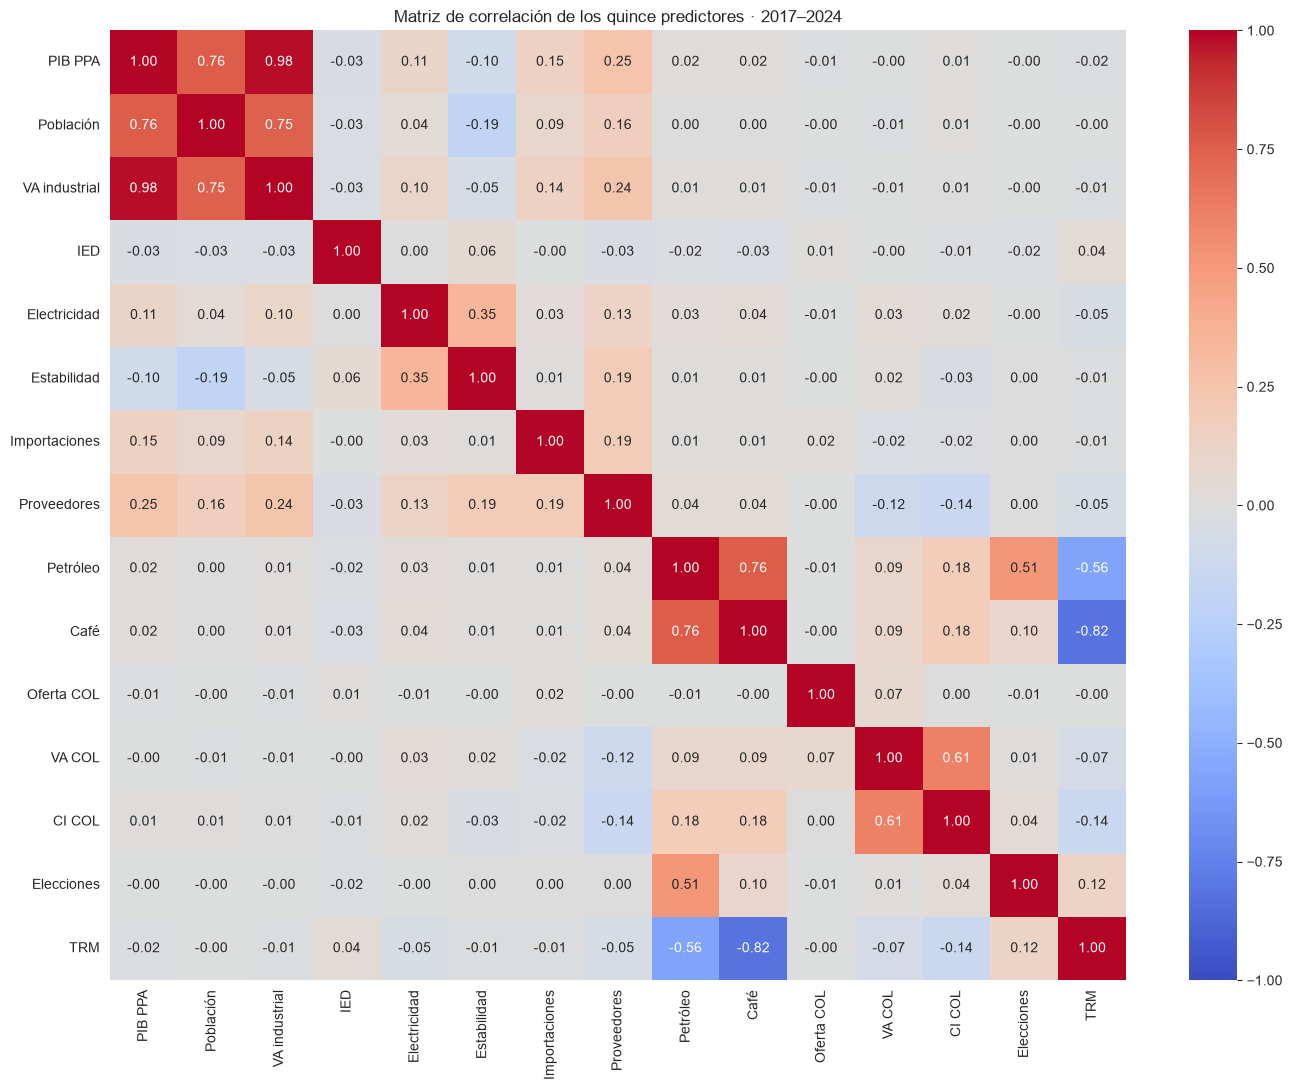

In [16]:
plt.figure(figsize = (14, 11))
sns.heatmap(correlacion, annot = True, cmap = 'coolwarm', fmt = '.2f', vmin = -1, vmax = 1)
plt.title('Matriz de correlación de los quince predictores · 2017–2024')
plt.tight_layout()
plt.savefig(REPORTS / 'correlacion_ml.png', dpi = 180)
plt.show()

## Graficar las relaciones entre los predictores

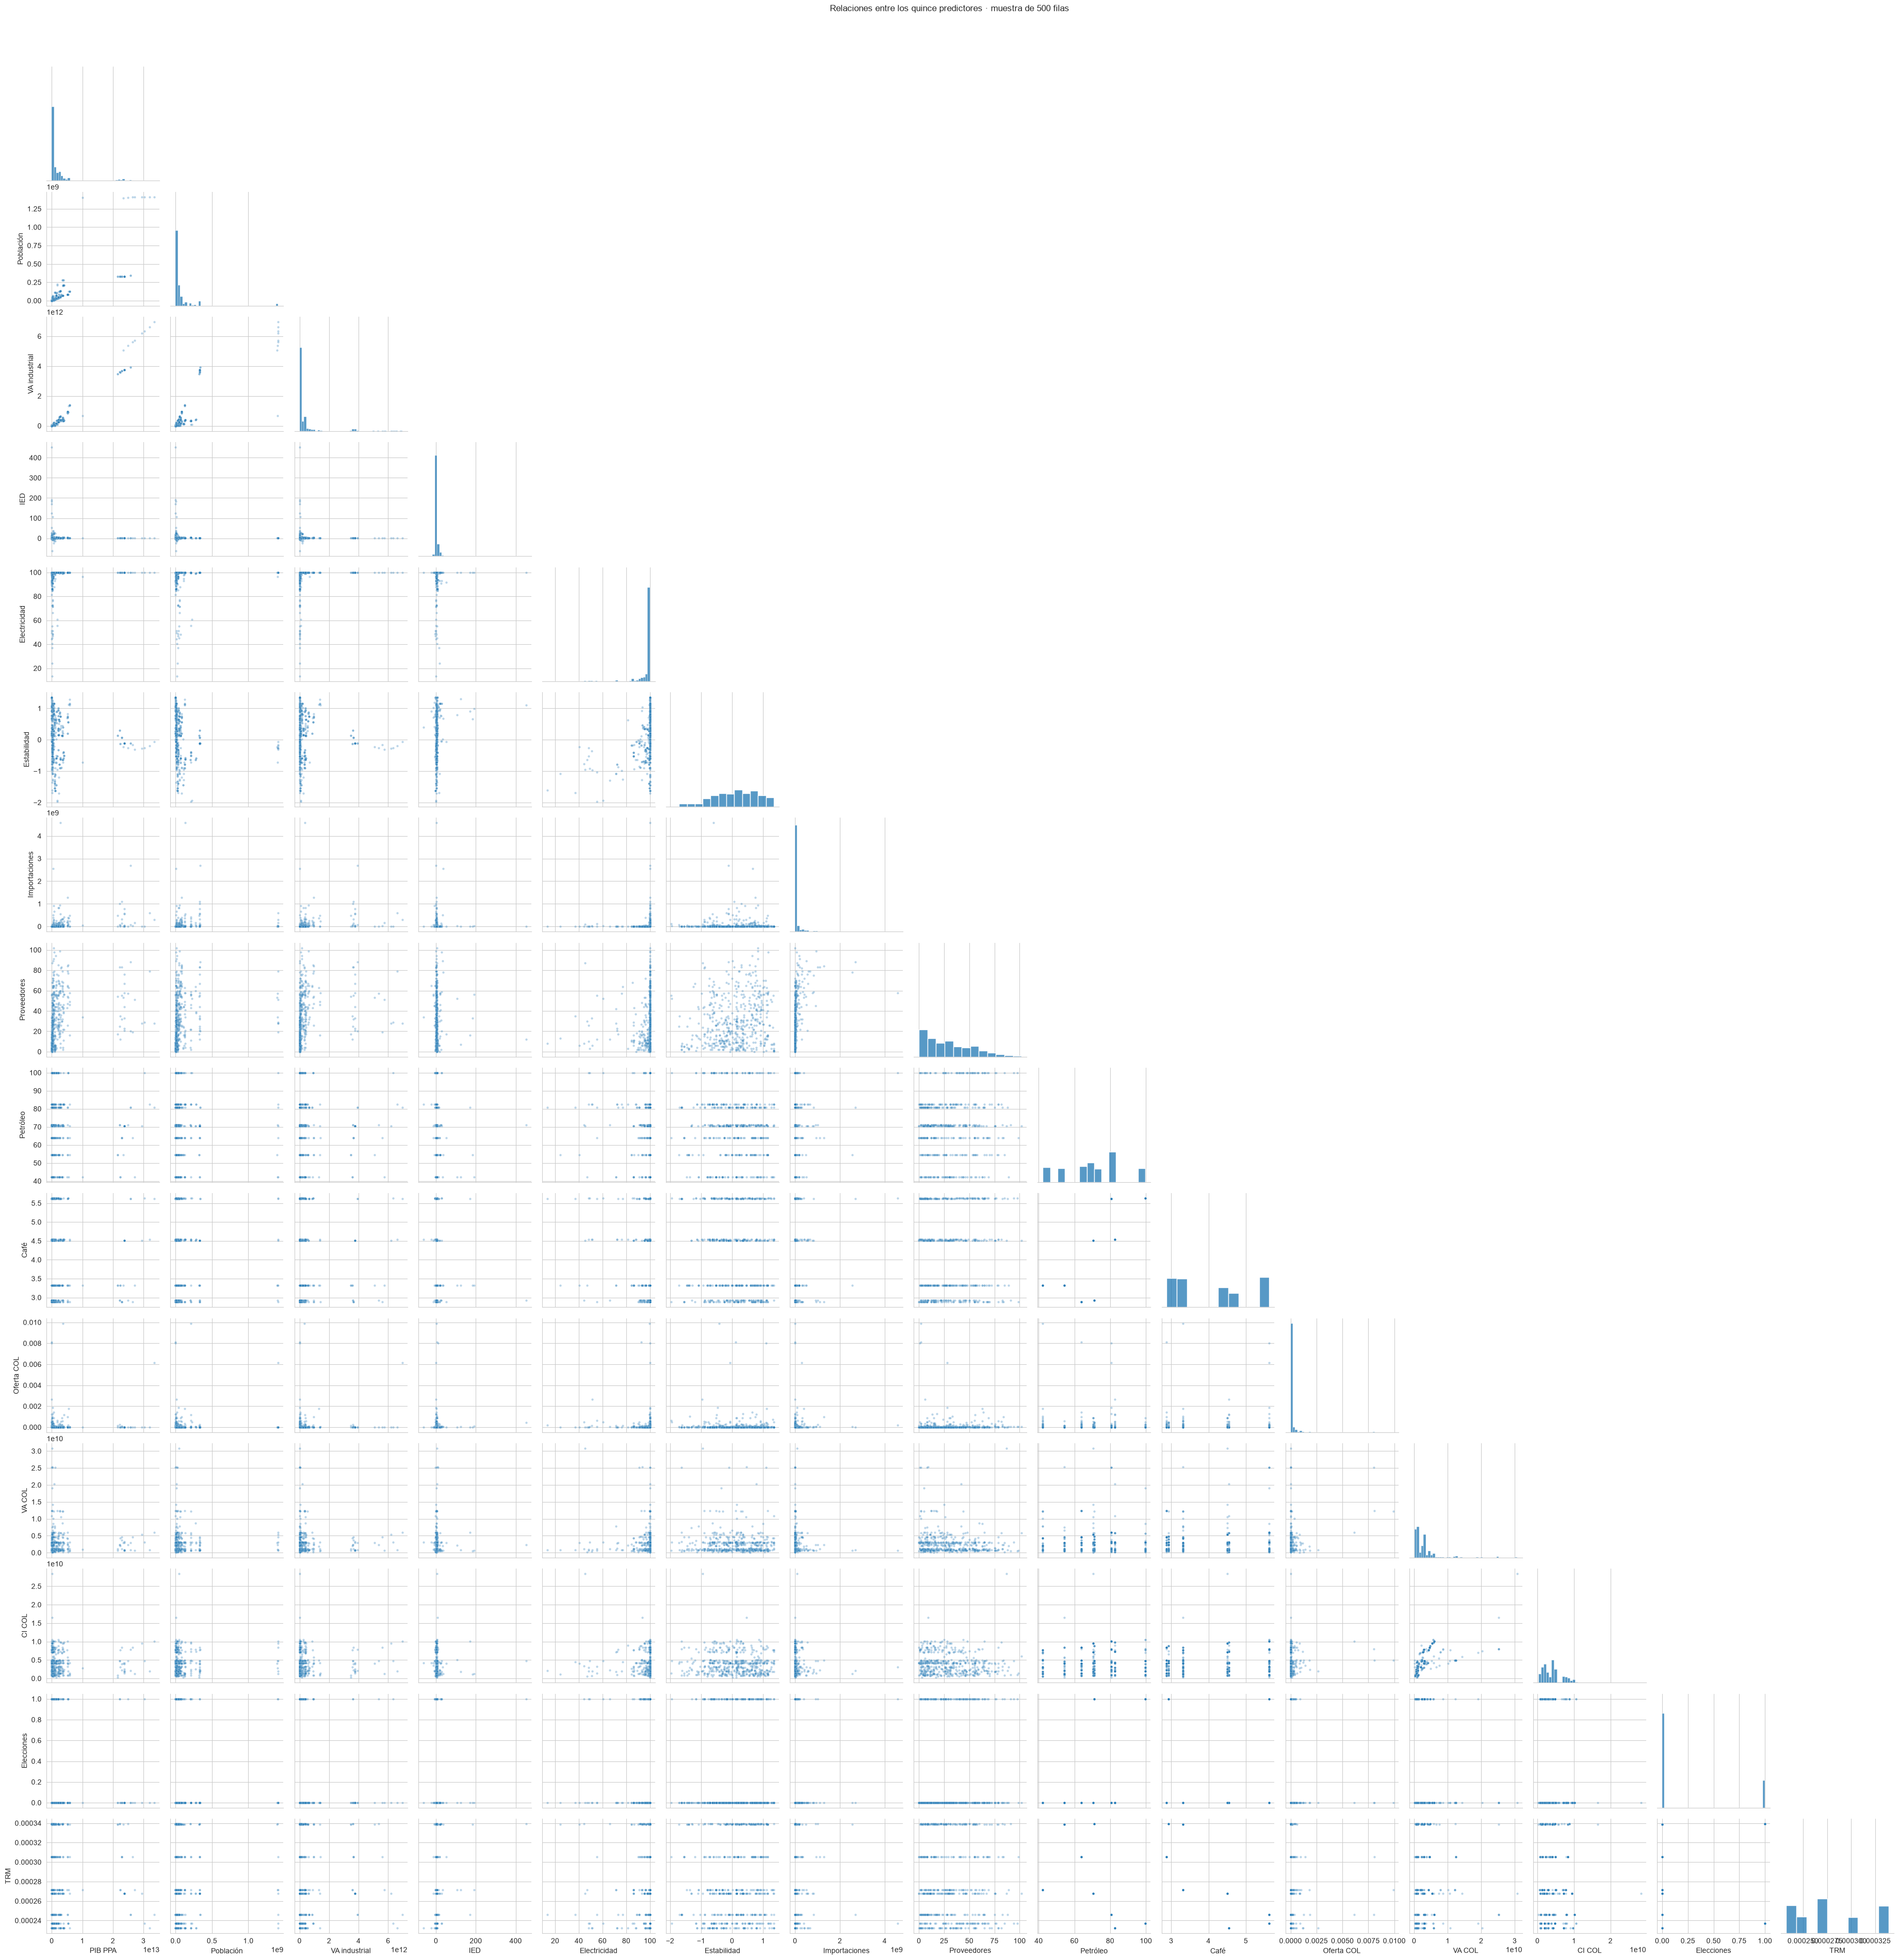

In [17]:
# Muestra reproducible únicamente para el gráfico.
sns.pairplot(base_ml.sample(500, random_state = 42).rename(columns = variables),
    vars = list(variables.values()), diag_kind = 'hist', corner = True,
    plot_kws = {'alpha': .3, 's': 10})
plt.suptitle('Relaciones entre los quince predictores · muestra de 500 filas', y = 1.02)
plt.savefig(REPORTS / 'pairplot_ml.png', dpi = 120, bbox_inches = 'tight')
plt.show()